# CO₂ histórico frente a un solo core · theta_nv2 congelado

Se comparan **Histórica · dos cores** (azul) y **Propuesta · un core, sin O₂** (verde). Cada formulación se reajusta por separado sólo con CO₂ de LAB019–021; LAB016–018 se reservan como holdout y no participan en optimización, selección de arranque ni decisión de etapa.

Una simulación química es integrar los cinco estados X,N,G,F,E. La histórica integra dos veces: con dosis reales y sin esas dosis. La propuesta integra **una sola vez, con las dosis reales**. Su contexto no contiene la trayectoria sin adiciones y su función de fuente no puede acceder a ella. Durante el ajuste se reutilizan estas químicas congeladas: no se vuelve a calibrar theta.

**Dos etapas, con figuras separadas:** E1 ajusta kCO2_release_h, CO2sat_scale y matrix_gain, fijando actividad y transitorio en sus valores históricos. E2 ajusta esos tres más pulse_activity_gain, pulse_t_rise_h, A, tau_rise_h y tau_decay_h. Las mismas cotas/arranques se aplican a ambas formulaciones. Las nuevas cotas nutricionales son decisiones exploratorias de este ensayo, no valores deducidos de literatura. No se impone tau_rise<tau_decay: son escalas de dos factores distintos. E2 se informa junto a E1; no se selecciona una etapa según el holdout.

## Ecuaciones exactas del ensayo

La química en ambos casos es la histórica de cinco estados, con mortalidad y sin estados de biomasa muerta o glicerol. Se imprime theta_nv2 físico completo; no se cambian sus rendimientos ni otros parámetros.
\[
\dot X=(\mu-k_d)X,\quad \dot N=-\mu X/Y_{X/N},
\]
\[
\dot G=-[\mu/Y_{X/G}+\beta_G/Y_{E/G}+m_{\rm ef}G/(G+F+\varepsilon)]X,
\]
\[
\dot F=-[\mu/Y_{X/F}+\beta_F/Y_{E/F}+m_{\rm ef}F/(G+F+\varepsilon)]X,\quad
\dot E=(\beta_G+\beta_F)X.
\]
En la trayectoria nutrida \(N(t_p^+)=N(t_p^-)+\Delta N_p\). La simulación adicional histórica omite sólo esos pulsos. Definimos \(q=(44.01/46.07)(\beta_G+\beta_F)X\), evaluado en cada trayectoria correspondiente.

La rampa histórica empieza en el primer pulso, \(r=\operatorname{clip}((t-t_{p,1})/t_{\rm rise},0,1)\), y \(a=1+(a_\infty-1)r\).
\[
M(t)=1+A\sum_p\frac{\Delta N_p}{N_{\rm ref}}
\frac{(1-e^{-u_p/\tau_r})e^{-u_p/\tau_d}}{h_{\max}},\qquad
u_p=\max(t-t_p,0),
\]
con máximo analítico de la función; Nref queda fijo.
\[
q_{\rm prod,hist}=\mathrm{gate}\,f_{O_2}\,M\,
\max[a q_0+r(q_N-q_0),0].
\]
\[
\boxed{q_{\rm prod,un\ core}=\mathrm{gate}\,a\,M
(44.01/46.07)(\beta_G+\beta_F)X.}
\]
No se añade contribución de crecimiento al CO₂: se conserva la fuente fermentativa histórica. La propuesta retira O₂ además de eliminar core0; no es un ensayo que aísle exclusivamente el número de integraciones.

Para ambas:
\[
C_{\rm sat}=s\,1.69\exp[-0.032(T-20)+0.0016E-0.0012(G+F)],
\]
\[
q_{\rm gas}=kC_d[0.05+0.95C_d/(C_d+C_{\rm sat})],\quad
\dot C_d=q_{\rm prod}-q_{\rm gas},\quad
q_{\rm medido}=gq_{\rm gas}.
\]
La saturación es la correlación provisional histórica, no una nueva medición. La liberación histórica permite gas bajo Csat. Cd inicial=0 en los seis LAB; integración conservativa implícita del mismo depósito. Se comprueba balance numérico.

## Datos y política común

- Medianas horarias de RAW convertida a g/(L·h) usando volumen remanente, leídas del CSV ya existente; líneas negras unidas. No se filtra la predicción ni se usa la señal GUI filtrada como objetivo.
- Horizonte del lector histórico: incluye última muestra offline y confirma cola baja (≤0.02 durante 2 h), sin truncar por predicción. Se imprimen cortes, observaciones y eventos efectivos.
- Si observación<0.05 g/(L·h), residuo=max(predicción−0.05,0); en las demás, predicción−observación. Se minimiza suma de MSE por laboratorio, igual peso por LAB.
- Mismas condiciones iniciales y temperaturas de logs procesadas por el lector histórico (mediana centrada 20 min y media centrada 45 min, no temperatura offline); no constituyen un procesamiento listo para EKF en tiempo real.
- Se conserva el gate histórico de consumo predicho 2–10 g/L, fijo en ambas. No se introduce onset manual ni se optimiza activación en este ensayo.
- Calendario/dosis de LAB019–021 se toman del lector histórico sin renormalización adicional. LAB017 se consolida en **un pulso de 0.28 g/L** al primer horario registrado, aplicado en ambos casos; se imprime la corrección común.
- Las químicas y sus muestras de LAB019–021 son validación, no objetivos del ajuste. Se incluyen todas las muestras numéricas por variable, incluidas NUT. En LAB016–018 se incluye biomasa experimental y G+F por densidad; no se inventan muestras individuales G/F.
- Sin archivos de resultados, CSV o PNG externos; parámetros completos, trazabilidad y tablas permanecen en EXECUTED. Modelos, parámetros y notebooks previos quedan protegidos por hashes.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from scipy.optimize import least_squares
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation.models.historical import co2 as gas
from wine_fermentation.models.historical import kinetics as kinetics
from wine_fermentation.models.historical.calibration import load,release_forward,Search,GAS_NAMES,GAS_BOUNDS
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
NAME='09_historical_single_core'
protected=[p for folder in ('src','configs','data','notebooks','results') for p in (ROOT/folder).rglob('*')
 if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
before={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
v=load(ROOT)
theta=kinetics.normalize_parameters(json.loads((ROOT/'configs/theta/theta_nv2.json').read_text()))
theta_before=theta.copy()
assert 0<theta['Yeg']<=.5114 and 0<theta['Yef']<=.5114
BASE=dict(v.old)
saved=json.loads((ROOT/'configs/models/historical/gas_fit.json').read_text())['experiments']['train_019_021']
BASE.update({k:float(saved[k]) for k in GAS_NAMES})
LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLDOUT=LABS[3:]
CASES=['Histórica · dos cores','Propuesta · un core, sin O₂']
COLORS={CASES[0]:'#0072B2',CASES[1]:'#009E73'}
batches=dict(v.batches)
e=batches['LAB017'].pulses['N']
assert np.isclose(sum(d for t,d in e),.28)
batches['LAB017']=replace(batches['LAB017'],pulses={**batches['LAB017'].pulses,'N':((min(t for t,d in e),.28),)})
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',
 usecols=['lab','time_h','record_kind','co2_raw_g_l_h'])
observed=observations(raw)
support={lab:observed[lab].loc[observed[lab].time_h.between(0,v.horizons[lab])].copy() for lab in LABS}
assert all(len(support[lab])>0 for lab in LABS)
display(pd.Series(theta,name='theta_nv2 físico · congelado'))
display(pd.DataFrame([dict(LAB=lab,**batches[lab].initials,eventos_N=batches[lab].pulses['N'],
 T_inicial_C=batches[lab].temperature_c[0],corte_h=v.horizons[lab],n_CO2=len(support[lab]),
 ultima_muestra_h=next(r['last_chemical_or_offline_h'] for r in v.coverage_rows if r['lab']==lab)) for lab in LABS]))
display(pd.Series({k:BASE[k] for k in [*GAS_NAMES,'pulse_activity_gain','pulse_t_rise_h','A','tau_rise_h','tau_decay_h','N_ref_g_l','O2_initial_scale','O2_qmax_mg_gdw_h']},name='Arranque común'))


mu0         0.082780
betaG0      0.412766
betaF0      0.447244
Kn0         0.008996
Kg0         4.400775
Kf0        19.296084
Kig0      122.553899
Kie0      286.579410
Kd0         0.000228
Yxn         5.179898
Yxg         0.966094
Yxf         1.109896
Yeg         0.482075
Yef         0.483728
m0          0.018339
Name: theta_nv2 físico · congelado, dtype: float64

,LAB,X,N,G,F,E,eventos_N,T_inicial_C,corte_h,n_CO2,ultima_muestra_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08),)",18.002222,166.000000,166,166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08),)",15.980556,172.333333,172,166.000000
2,LAB021,0.136153,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08),)",21.020000,166.000000,166,166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",20.159259,151.100000,152,56.184722
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",19.776667,141.000000,141,56.183333
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",19.775389,141.000000,141,56.181389


kCO2_release_h          1.229635
CO2sat_scale            2.500000
matrix_gain             0.836671
pulse_activity_gain     0.250000
pulse_t_rise_h         64.658704
A                       0.300000
tau_rise_h              4.000000
tau_decay_h            12.000000
N_ref_g_l               0.140000
O2_initial_scale        0.195400
O2_qmax_mg_gdw_h        0.150000
Name: Arranque común, dtype: float64

In [2]:
# Context builders are independent: the proposal has no counterfactual core.
integration_calls={CASES[0]:0,CASES[1]:0}
def integrate(batch,case):
 integration_calls[case]+=1
 f=gas.integrate_core(batch,theta,batch.time);f['GF']=f.G+f.F
 return f
def common_context(batch,core):
 consumed=core.GF.iloc[0]-core.GF.to_numpy()
 z=np.clip((consumed-2.)/8.,0.,1.)
 return dict(time=core.index.to_numpy(float),dt=np.diff(core.index),gate=z*z*(3.-2.*z),
  q=gas.production(theta,batch,core),sat_base=gas.csat(batch,core,{'CO2sat_scale':1.}),
  events=batch.pulses['N'],core=core)
def oxygen_factor(batch,core,core0,ramp):
 time=core.index.to_numpy();oxygen=np.zeros(len(time))
 ini=batch.initials
 oxygen[0]=BASE['O2_initial_scale']*gas.o2_saturation_mg_l(batch.temperature_c[0],ini['E'],ini['G'],ini['F'])
 biomass=np.maximum(core0.X.to_numpy()+ramp*(core.X-core0.X).to_numpy(),0.)
 for i,dt in enumerate(np.diff(time)):
  uptake=BASE['O2_qmax_mg_gdw_h']*biomass[i]*oxygen[i]/(.25+oxygen[i])
  oxygen[i+1]=max(oxygen[i]-dt*uptake,0.)
 return .08+.92*.75**2/(.75**2+oxygen**2)
def build_historical(batch):
 core=integrate(batch,CASES[0])
 core0=integrate(replace(batch,pulses={**batch.pulses,'N':()}),CASES[0])
 c=common_context(batch,core);c['q0']=gas.production(theta,batch,core0)
 r,_=Search.histories(c['time'],c['events'],BASE)
 c['fferm']=oxygen_factor(batch,core,core0,r)
 from functools import lru_cache
 @lru_cache(maxsize=16)
 def oxygen_for_rise(rise):
  rr,_=Search.histories(c['time'],c['events'],{**BASE,'pulse_t_rise_h':rise})
  return oxygen_factor(batch,core,core0,rr)
 c['oxygen_for_rise']=oxygen_for_rise
 # Verify exact historical source implementation at nominal parameters.
 rr,mm=Search.histories(c['time'],c['events'],BASE)
 ini=batch.initials;oxygen0=BASE['O2_initial_scale']*gas.o2_saturation_mg_l(batch.temperature_c[0],ini['E'],ini['G'],ini['F'])
 reference=gas.finish(batch,theta,core,core0,BASE,c['gate'],rr,mm,0.,oxygen0)
 expected=c['gate']*c['fferm']*mm*np.maximum((1+(BASE['pulse_activity_gain']-1)*rr)*c['q0']+rr*(c['q']-c['q0']),0)
 assert np.allclose(reference.qprod,expected,rtol=1e-12,atol=1e-12)
 return c
def build_single(batch):
 core=integrate(batch,CASES[1])
 return common_context(batch,core)

contexts={}
for lab in LABS:
 contexts[CASES[0],lab]=build_historical(batches[lab])
 contexts[CASES[1],lab]=build_single(batches[lab])
 assert not {'q0','core0','fferm','oxygen0'}.intersection(contexts[CASES[1],lab])
 pd.testing.assert_frame_equal(contexts[CASES[0],lab]['core'],contexts[CASES[1],lab]['core'])
assert integration_calls=={CASES[0]:12,CASES[1]:6}
display(pd.Series(integration_calls,name='Integraciones químicas para los seis LAB'))
def source(case,c,p):
 r,M=Search.histories(c['time'],c['events'],p)
 a=1+(p['pulse_activity_gain']-1)*r
 if case==CASES[1]:return c['gate']*a*M*c['q']
 return c['gate']*c['oxygen_for_rise'](float(p['pulse_t_rise_h']))*M*np.maximum(a*c['q0']+r*(c['q']-c['q0']),0.)
def predict(case,lab,p):
 c=contexts[case,lab]
 src=source(case,c,p)
 pred,cd,qgas=release_forward({'source':src,'dt':c['dt'],'sat_base':c['sat_base']},p)
 return pd.DataFrame(dict(qpred=pred,Cd=cd,qgas=qgas,qprod=src,Csat=c['sat_base']*p['CO2sat_scale']),index=c['time'])
# Historical reservoir agrees with its unchanged implicit implementation.
for lab in LABS:
 c=contexts[CASES[0],lab];f=predict(CASES[0],lab,BASE)
 expected=release_forward({**c,'source':source(CASES[0],c,BASE)},BASE)
 assert np.array_equal(f.qpred.to_numpy(),expected[0])
assert theta==theta_before


Histórica · dos cores          12
Propuesta · un core, sin O₂     6
Name: Integraciones químicas para los seis LAB, dtype: int64

## Recalibración en dos etapas

E1: tres parámetros de depósito/escala. E2: los mismos más cinco parámetros nutricionales. Los parámetros específicos de O₂ histórico están fijos en sus valores heredados; su evolución se recalcula si cambia la rampa nutricional, porque ésta modifica la biomasa usada por el consumo de O₂. La propuesta no contiene ese factor.

Tres arranques por etapa y formulación, todos derivados de valores comunes y del mejor E1 correspondiente. E2 conserva E1 si el optimizador no mejora su objetivo. La selección sólo consulta LAB019–021. Las cotas y las terminaciones se muestran, incluyendo problemas de identificabilidad mediante valores singulares del Jacobiano.

In [3]:
NUT_NAMES=('pulse_activity_gain','pulse_t_rise_h','A','tau_rise_h','tau_decay_h')
NUT_BOUNDS=((.05,1.5),(6.,120.),(1e-6,2.),(.25,24.),(1.,72.))
BOUNDS=dict(zip((*GAS_NAMES,*NUT_NAMES),(*GAS_BOUNDS,*NUT_BOUNDS)))
display(pd.DataFrame([dict(parametro=k,arranque=BASE[k],minimo=a,maximo=b,
 tipo='Cota histórica existente' if k in GAS_NAMES or k in NUT_NAMES[:2] else 'Cota exploratoria del diagnóstico') for k,(a,b) in BOUNDS.items()]))
def residual(case,p,labs):
 assert tuple(labs)==tuple(TRAIN),'Only calibration laboratories in optimizer'
 parts=[]
 for lab in labs:
  f=predict(case,lab,p);o=support[lab];y=o.co2_raw_g_l_h.to_numpy()
  yp=np.interp(o.time_h,f.index,f.qpred)
  e=np.where(y<.05,np.maximum(yp-.05,0.),yp-y)
  parts.append(e/np.sqrt(len(e)))
 return np.concatenate(parts)
fits={};fitrows=[];runrows=[];jacrows=[]
for case in CASES:
 for stage,names in [('E1',GAS_NAMES),('E2',(*GAS_NAMES,*NUT_NAMES))]:
  lo,hi=np.asarray([BOUNDS[k] for k in names]).T
  template=dict(BASE if stage=='E1' else fits[case,'E1'])
  seeds=[dict(template),{**template,'kCO2_release_h':.4,'CO2sat_scale':1.,'matrix_gain':.7},
   {**template,'kCO2_release_h':2.,'CO2sat_scale':1.,'matrix_gain':1.}]
  if stage=='E2':
   seeds[1].update(pulse_activity_gain=.6,pulse_t_rise_h=24.,A=.2,tau_rise_h=2.,tau_decay_h=8.)
   seeds[2].update(pulse_activity_gain=1.,pulse_t_rise_h=48.,A=.5,tau_rise_h=4.,tau_decay_h=12.)
  sols=[]
  for j,seed in enumerate(seeds):
   def objective(x):return residual(case,{**template,**dict(zip(names,np.exp(x)))},TRAIN)
   sol=least_squares(objective,np.log(np.clip([seed[k] for k in names],lo+1e-10,hi-1e-10)),
    bounds=(np.log(lo),np.log(hi)),diff_step=1e-4,max_nfev=120,ftol=1e-7,xtol=1e-7,gtol=1e-7)
   sols.append(sol)
   runrows.append(dict(caso=case,etapa=stage,arranque=j,success=bool(sol.success),nfev=sol.nfev,
    objetivo=float(sol.fun@sol.fun),optimality=float(sol.optimality),message=sol.message))
   print(case,stage,'arranque',j,runrows[-1],flush=True)
  win=min(sols,key=lambda x:float(x.fun@x.fun))
  candidate={**template,**dict(zip(names,np.exp(win.x)))}
  previous=float(residual(case,template,TRAIN)@residual(case,template,TRAIN))
  fitted=float(win.fun@win.fun)
  use_previous=previous<fitted
  fits[case,stage]=template if use_previous else candidate
  pp=fits[case,stage];obj=residual(case,pp,TRAIN)
  singular=np.linalg.svd(win.jac,compute_uv=False)
  close=[k for k,x,a,b in zip(names,[pp[k] for k in names],lo,hi) if min(abs(np.log(x/a)),abs(np.log(b/x)))<.02]
  fitrows.append(dict(caso=case,etapa=stage,objetivo=float(obj@obj),success=bool(win.success),
   conserva_anterior=use_previous,cerca_limites=','.join(close),ratio_singular=float(singular[-1]/singular[0]),
   **{k:float(pp[k]) for k in (*GAS_NAMES,*NUT_NAMES)}))
  for i,x in enumerate(singular):jacrows.append(dict(caso=case,etapa=stage,indice=i,valor_singular=x))
  assert float(obj@obj)<=previous+1e-9
display(pd.DataFrame(runrows));display(pd.DataFrame(fitrows));display(pd.DataFrame(jacrows))
print('PARAMETROS_COMPLETOS_SIN_EXPORTACION')
print(json.dumps([dict(caso=c,etapa=s,parametros=p) for (c,s),p in fits.items()],ensure_ascii=False,indent=2))
assert theta==theta_before
assert integration_calls=={CASES[0]:12,CASES[1]:6}


,parametro,arranque,minimo,maximo,tipo
0,kCO2_release_h,1.229635,0.030000,25.0,Cota histórica existente
1,CO2sat_scale,2.500000,0.350000,2.5,Cota histórica existente
2,matrix_gain,0.836671,0.100000,20.0,Cota histórica existente
3,pulse_activity_gain,0.250000,0.050000,1.5,Cota histórica existente
4,pulse_t_rise_h,64.658704,6.000000,120.0,Cota histórica existente
5,A,0.300000,0.000001,2.0,Cota exploratoria del diagnóstico
6,tau_rise_h,4.000000,0.250000,24.0,Cota exploratoria del diagnóstico
7,tau_decay_h,12.000000,1.000000,72.0,Cota exploratoria del diagnóstico


Histórica · dos cores E1 arranque 0 {'caso': 'Histórica · dos cores', 'etapa': 'E1', 'arranque': 0, 'success': True, 'nfev': 3, 'objetivo': 0.06427100102951046, 'optimality': 2.0383708610575185e-06, 'message': '`ftol` termination condition is satisfied.'}


Histórica · dos cores E1 arranque 1 {'caso': 'Histórica · dos cores', 'etapa': 'E1', 'arranque': 1, 'success': True, 'nfev': 7, 'objetivo': 0.06427100068057623, 'optimality': 7.10966292113893e-07, 'message': '`ftol` termination condition is satisfied.'}


Histórica · dos cores E1 arranque 2 {'caso': 'Histórica · dos cores', 'etapa': 'E1', 'arranque': 2, 'success': True, 'nfev': 7, 'objetivo': 0.06427100086999255, 'optimality': 1.2792628725767021e-06, 'message': '`ftol` termination condition is satisfied.'}


Histórica · dos cores E2 arranque 0 {'caso': 'Histórica · dos cores', 'etapa': 'E2', 'arranque': 0, 'success': True, 'nfev': 11, 'objetivo': 0.05592361366147961, 'optimality': 4.677689478407608e-09, 'message': '`gtol` termination condition is satisfied.'}


Histórica · dos cores E2 arranque 1 {'caso': 'Histórica · dos cores', 'etapa': 'E2', 'arranque': 1, 'success': True, 'nfev': 16, 'objetivo': 0.05592361366318922, 'optimality': 2.52959612533116e-09, 'message': '`gtol` termination condition is satisfied.'}


... (7 outputs left out)

,caso,etapa,arranque,success,nfev,objetivo,optimality,message
0,Histórica · dos cores,E1,0,True,3,0.064271,2.038371e-06,`ftol` termination condition is satisfied.
1,Histórica · dos cores,E1,1,True,7,0.064271,7.109663e-07,`ftol` termination condition is satisfied.
2,Histórica · dos cores,E1,2,True,7,0.064271,1.279263e-06,`ftol` termination condition is satisfied.
3,Histórica · dos cores,E2,0,True,11,0.055924,4.677689e-09,`gtol` termination condition is satisfied.
4,Histórica · dos cores,E2,1,True,16,0.055924,2.529596e-09,`gtol` termination condition is satisfied.
5,Histórica · dos cores,E2,2,True,12,0.055924,1.132986e-08,`gtol` termination condition is satisfied.
6,"Propuesta · un core, sin O₂",E1,0,True,5,0.059430,1.235877e-07,`ftol` termination condition is satisfied.
7,"Propuesta · un core, sin O₂",E1,1,True,7,0.059430,7.903940e-09,`gtol` termination condition is satisfied.
8,"Propuesta · un core, sin O₂",E1,2,True,8,0.059430,3.021664e-08,`gtol` termination condition is satisfied.
9,"Propuesta · un core, sin O₂",E2,0,True,11,0.056657,2.932138e-06,`ftol` termination condition is satisfied.


,caso,etapa,objetivo,success,conserva_anterior,cerca_limites,ratio_singular,kCO2_release_h,CO2sat_scale,matrix_gain,pulse_activity_gain,pulse_t_rise_h,A,tau_rise_h,tau_decay_h
0,Histórica · dos cores,E1,0.064271,True,False,CO2sat_scale,0.002690,1.217553,2.50,0.837994,0.250000,64.658704,0.300000,4.00,12.000000
1,Histórica · dos cores,E2,0.055924,True,False,"kCO2_release_h,CO2sat_scale,pulse_activity_gai...",0.000158,25.000000,0.35,0.698482,0.050000,114.690555,1.297543,24.00,7.296109
2,"Propuesta · un core, sin O₂",E1,0.059430,True,False,CO2sat_scale,0.001388,2.348168,2.50,0.774287,0.250000,64.658704,0.300000,4.00,12.000000
3,"Propuesta · un core, sin O₂",E2,0.056657,True,False,"CO2sat_scale,tau_rise_h",0.002829,0.831795,2.50,0.746271,0.222743,61.503466,1.129288,0.25,8.472341


,caso,etapa,indice,valor_singular
0,Histórica · dos cores,E1,0,0.551287
1,Histórica · dos cores,E1,1,0.028860
2,Histórica · dos cores,E1,2,0.001483
3,Histórica · dos cores,E2,0,0.577894
4,Histórica · dos cores,E2,1,0.128660
5,Histórica · dos cores,E2,2,0.101916
6,Histórica · dos cores,E2,3,0.085323
7,Histórica · dos cores,E2,4,0.001551
8,Histórica · dos cores,E2,5,0.001278
9,Histórica · dos cores,E2,6,0.000565


PARAMETROS_COMPLETOS_SIN_EXPORTACION
[
  {
    "caso": "Histórica · dos cores",
    "etapa": "E1",
    "parametros": {
      "kCO2_release_h": 1.2175529940586693,
      "CO2sat_scale": 2.499999998391437,
      "O2_qmax_mg_gdw_h": 0.15,
      "O2_initial_scale": 0.1953996656508908,
      "pulse_t_rise_h": 64.65870374633818,
      "pulse_activity_gain": 0.25,
      "chem_activation_start_fraction": 0.735056695858678,
      "chem_activation_duration_fraction": 1.063909868135744,
      "matrix_gain": 0.8379938521611076,
      "A": 0.3,
      "tau_rise_h": 4.0,
      "tau_decay_h": 12.0,
      "N_ref_g_l": 0.14,
      "kernel_normalization": "analytic_peak",
      "activation_start_g_l": 2.0,
      "activation_width_g_l": 8.0
    }
  },
  {
    "caso": "Histórica · dos cores",
    "etapa": "E2",
    "parametros": {
      "kCO2_release_h": 24.99999999997425,
      "CO2sat_scale": 0.3500000000000278,
      "O2_qmax_mg_gdw_h": 0.15,
      "O2_initial_scale": 0.1953996656508908,
      "pulse_t_

In [4]:
curves={};metrics=[];segments=[]
for (case,stage),p in fits.items():
 for lab in LABS:
  f=predict(case,lab,p);curves[case,stage,lab]=f;c=contexts[case,lab];o=support[lab]
  assert np.max(abs(np.diff(f.Cd)-np.diff(f.index)*(f.qprod.to_numpy()[:-1]-f.qgas.to_numpy()[1:])))<1e-9
  assert f.Cd.iloc[0]==0 and f.qgas.min()>-1e-12 and f.Cd.min()>=0
  y=o.co2_raw_g_l_h.to_numpy();yp=np.interp(o.time_h,f.index,f.qpred);e=yp-y
  cens=np.where(y<.05,np.maximum(yp-.05,0.),e)
  t=o.time_h.to_numpy();pulse=c['events'][0][0];first_peak=int(np.argmax(y))
  pre=t<pulse;after=t>=pulse
  metrics.append(dict(caso=case,etapa=stage,LAB=lab,rol='Calibración' if lab in TRAIN else 'Holdout',
   n=len(y),RMSE=float(np.sqrt(np.mean(e*e))),RMSE_censurado=float(np.sqrt(np.mean(cens*cens))),
   sesgo=float(e.mean()),area_medida_g_L=float(np.trapz(y,t)),area_predicha_g_L=float(np.trapz(yp,t)),
   pico_medido=float(y.max()),pico_predicho=float(yp.max()),
   hora_pico_medida=float(t[first_peak]),hora_pico_predicha=float(t[np.argmax(yp)])))
  for label,m in [('Antes de nutrición',pre),('Desde nutrición',after),('Desde 100 h',t>=100)]:
   if not m.any():continue
   segments.append(dict(caso=case,etapa=stage,LAB=lab,tramo=label,n=int(m.sum()),
    RMSE=float(np.sqrt(np.mean(e[m]**2))),sesgo=float(e[m].mean())))
metrics=pd.DataFrame(metrics);segments=pd.DataFrame(segments)
display(metrics.round(6));display(segments.round(6))
display(metrics.groupby(['etapa','rol','caso'])[['RMSE','RMSE_censurado','sesgo','area_predicha_g_L']].mean().round(6))
# Validation chemistry is shared and cannot change when gas coefficients change.
chemical_metrics=[];sample_counts=[]
VARIABLES=[('E','Etanol',1.,'g/L'),('G','Glucosa',1.,'g/L'),('F','Fructosa',1.,'g/L'),
 ('GF','Glucosa + fructosa',1.,'g/L'),('X','Biomasa viable',1.,'g/L'),('N','YAN',1000.,'mg/L')]
def samples(lab,key):
 if lab in TRAIN:
  z=chemical_observations(v.chem,lab,key)
  return z.t_h.to_numpy(),z[CHEMICAL_COLUMNS[key]].to_numpy(),'Muestras experimentales'
 if key=='GF':
  z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
  return z.t_h.to_numpy(),2.5*(z.density_g_l.to_numpy()-1000),'G+F por densidad'
 if key=='X':
  z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l'])
  return z.t_h.to_numpy(),z.X_viable_g_l.to_numpy(),'Biomasa experimental'
 return np.array([]),np.array([]),'Sin muestras disponibles'
for lab in LABS:
 a=contexts[CASES[0],lab]['core'];b=contexts[CASES[1],lab]['core']
 assert np.array_equal(a.to_numpy(),b.to_numpy())
 for key,title,scale,unit in VARIABLES:
  t,y,label=samples(lab,key);sample_counts.append(dict(LAB=lab,variable=title,n=len(t),origen=label))
  m=(t>0)&(t<=a.index[-1])
  if m.any():
   e=(np.interp(t[m],a.index,a[key])-y[m])*scale
   chemical_metrics.append(dict(LAB=lab,variable=title,n=int(m.sum()),RMSE=float(np.sqrt(np.mean(e*e))),unidad=unit))
display(pd.DataFrame(sample_counts));display(pd.DataFrame(chemical_metrics))


,caso,etapa,LAB,rol,n,RMSE,RMSE_censurado,sesgo,area_medida_g_L,area_predicha_g_L,pico_medido,pico_predicho,hora_pico_medida,hora_pico_predicha
0,Histórica · dos cores,E1,LAB019,Calibración,166,0.148507,0.148095,0.020096,39.947815,43.300129,0.758905,0.639155,96.500556,70.523056
1,Histórica · dos cores,E1,LAB020,Calibración,172,0.051166,0.050513,0.000244,36.133230,36.180989,0.597467,0.564013,79.500278,77.500278
2,Histórica · dos cores,E1,LAB021,Calibración,166,0.200730,0.199467,-0.035889,40.168829,34.215746,1.087220,0.652759,52.500000,53.500278
3,Histórica · dos cores,E1,LAB016,Holdout,152,0.142853,0.141729,0.020589,46.204576,49.367029,0.798634,0.773613,46.499167,63.495000
4,Histórica · dos cores,E1,LAB017,Holdout,141,0.114128,0.113325,0.006986,51.174978,52.163646,0.853441,0.946504,63.495139,63.495139
5,Histórica · dos cores,E1,LAB018,Holdout,141,0.111755,0.111046,0.008875,48.014901,49.265829,0.811461,0.770707,43.499167,62.500833
6,Histórica · dos cores,E2,LAB019,Calibración,166,0.135360,0.134552,0.017483,39.947815,42.866610,0.758905,0.801064,96.500556,70.523056
7,Histórica · dos cores,E2,LAB020,Calibración,172,0.058862,0.057584,0.005506,36.133230,37.086754,0.597467,0.709001,79.500278,77.500278
8,Histórica · dos cores,E2,LAB021,Calibración,166,0.187890,0.185751,-0.026097,40.168829,35.840970,1.087220,0.821996,52.500000,53.500278
9,Histórica · dos cores,E2,LAB016,Holdout,152,0.184691,0.183562,0.035631,46.204576,51.656536,0.798634,1.154995,46.499167,63.495000


,caso,etapa,LAB,tramo,n,RMSE,sesgo
0,Histórica · dos cores,E1,LAB019,Antes de nutrición,64,0.189964,0.141954
1,Histórica · dos cores,E1,LAB019,Desde nutrición,102,0.115109,-0.056364
2,Histórica · dos cores,E1,LAB019,Desde 100 h,66,0.120431,-0.075007
3,Histórica · dos cores,E1,LAB020,Antes de nutrición,72,0.050355,0.020880
4,Histórica · dos cores,E1,LAB020,Desde nutrición,100,0.051741,-0.014614
...,...,...,...,...,...,...,...
67,"Propuesta · un core, sin O₂",E2,LAB017,Desde nutrición,84,0.297461,0.094813
68,"Propuesta · un core, sin O₂",E2,LAB017,Desde 100 h,41,0.073891,-0.056241
69,"Propuesta · un core, sin O₂",E2,LAB018,Antes de nutrición,57,0.158117,0.014677
70,"Propuesta · un core, sin O₂",E2,LAB018,Desde nutrición,84,0.160337,0.030069


RMSE  RMSE_censurado  \
etapa rol         caso                                                    
E1    Calibración Histórica · dos cores        0.133468        0.132692   
                  Propuesta · un core, sin O₂  0.130951        0.129149   
      Holdout     Histórica · dos cores        0.122912        0.122034   
                  Propuesta · un core, sin O₂  0.157588        0.156445   
E2    Calibración Histórica · dos cores        0.127371        0.125962   
                  Propuesta · un core, sin O₂  0.129549        0.128172   
      Holdout     Histórica · dos cores        0.214679        0.213873   
                  Propuesta · un core, sin O₂  0.195681        0.195050   

                                                  sesgo  area_predicha_g_L  
etapa rol         caso                                                      
E1    Calibración Histórica · dos cores       -0.005183          37.898955  
                  Propuesta · un core, sin O₂  0.003960          39.431830  
      Holdout     Histórica · dos cores        0.012150          50.265501  
                  Propuesta · un core, sin O₂  0.028228          52.570375  
E2    Calibración Histórica · dos cores       -0.001036          38.598112  
                  Propuesta · un core, sin O₂ -0.002051          38.419896  
      Holdout     Histórica · dos cores        0.045748          55.061697  
                  Propuesta · un core, sin O₂  0.039767          54.210292

,LAB,variable,n,origen
0,LAB019,Etanol,6,Muestras experimentales
1,LAB019,Glucosa,8,Muestras experimentales
2,LAB019,Fructosa,8,Muestras experimentales
3,LAB019,Glucosa + fructosa,12,Muestras experimentales
4,LAB019,Biomasa viable,11,Muestras experimentales
5,LAB019,YAN,13,Muestras experimentales
6,LAB020,Etanol,6,Muestras experimentales
7,LAB020,Glucosa,7,Muestras experimentales
8,LAB020,Fructosa,7,Muestras experimentales
9,LAB020,Glucosa + fructosa,12,Muestras experimentales


,LAB,variable,n,RMSE,unidad
0,LAB019,Etanol,5,11.790213,g/L
1,LAB019,Glucosa,7,2.599255,g/L
2,LAB019,Fructosa,7,3.519361,g/L
3,LAB019,Glucosa + fructosa,11,5.859407,g/L
4,LAB019,Biomasa viable,10,0.333142,g/L
5,LAB019,YAN,12,44.020632,mg/L
6,LAB020,Etanol,5,4.005146,g/L
7,LAB020,Glucosa,6,8.833357,g/L
8,LAB020,Fructosa,6,5.428427,g/L
9,LAB020,Glucosa + fructosa,11,9.518108,g/L


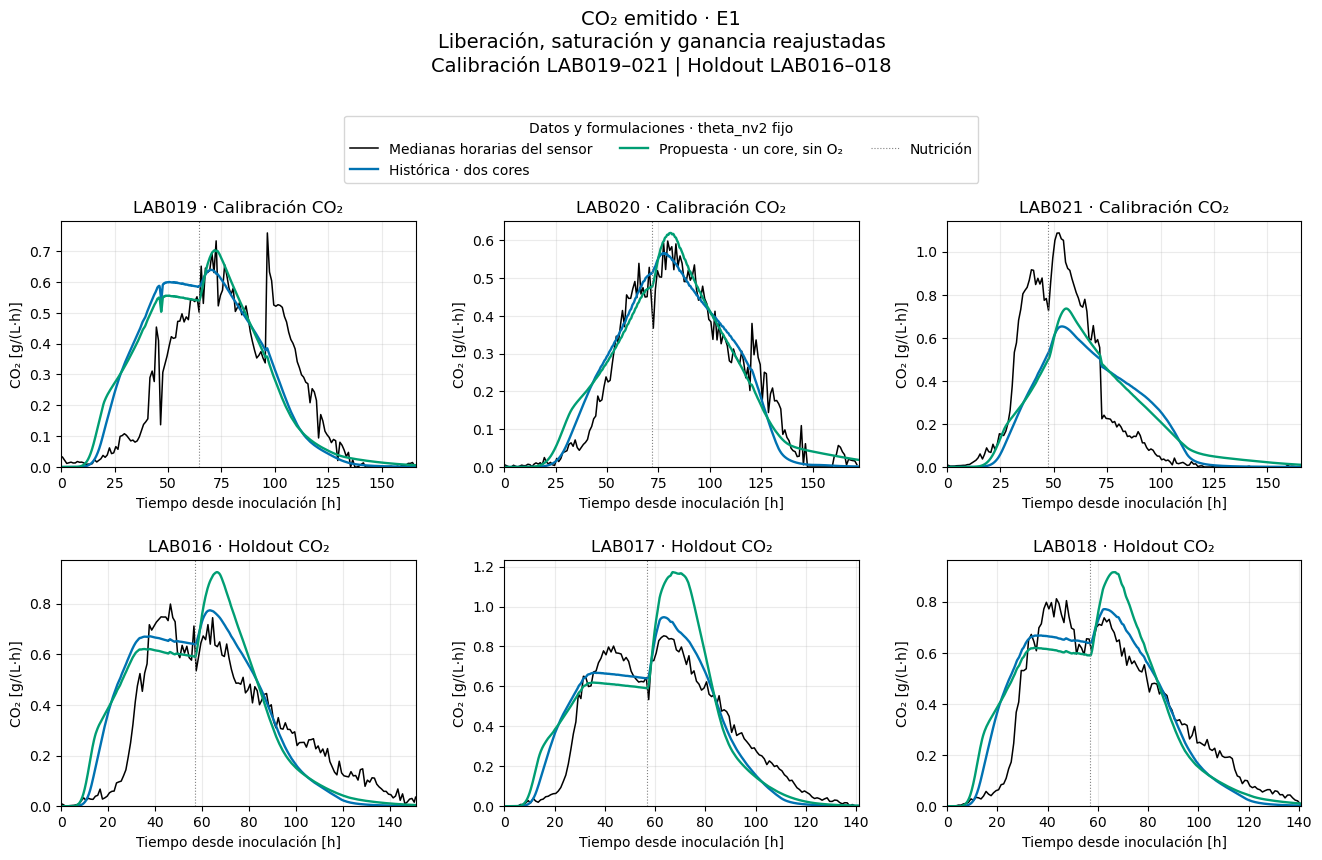

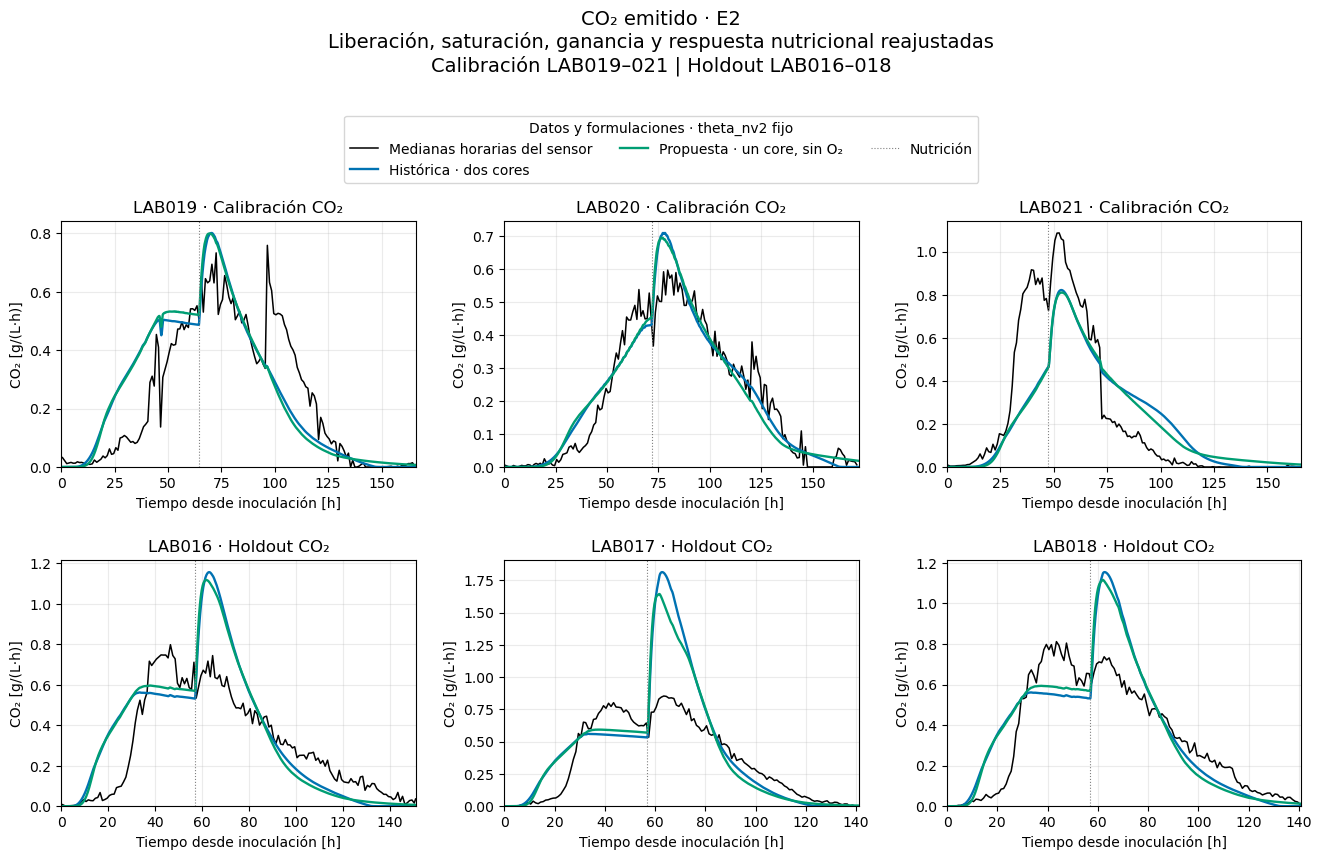

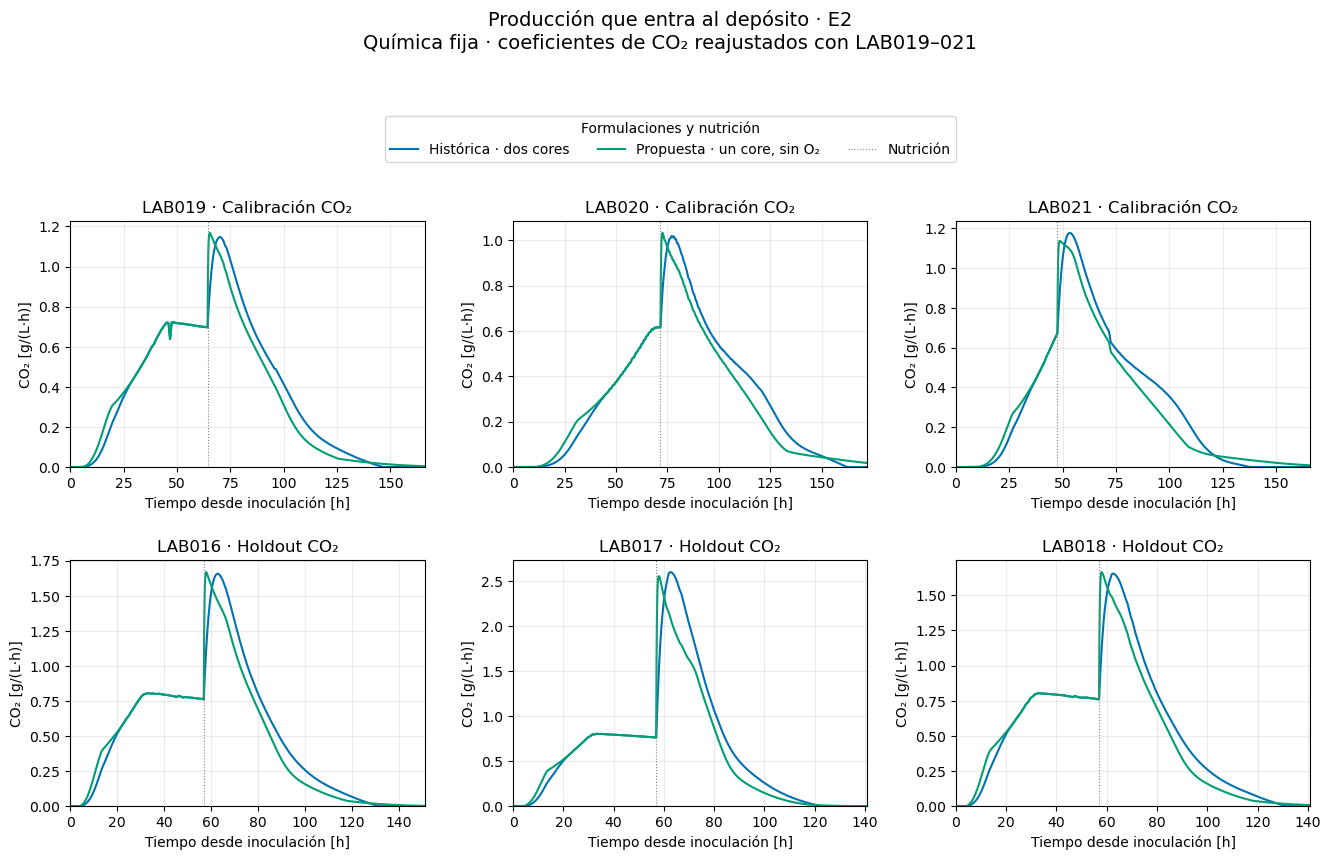

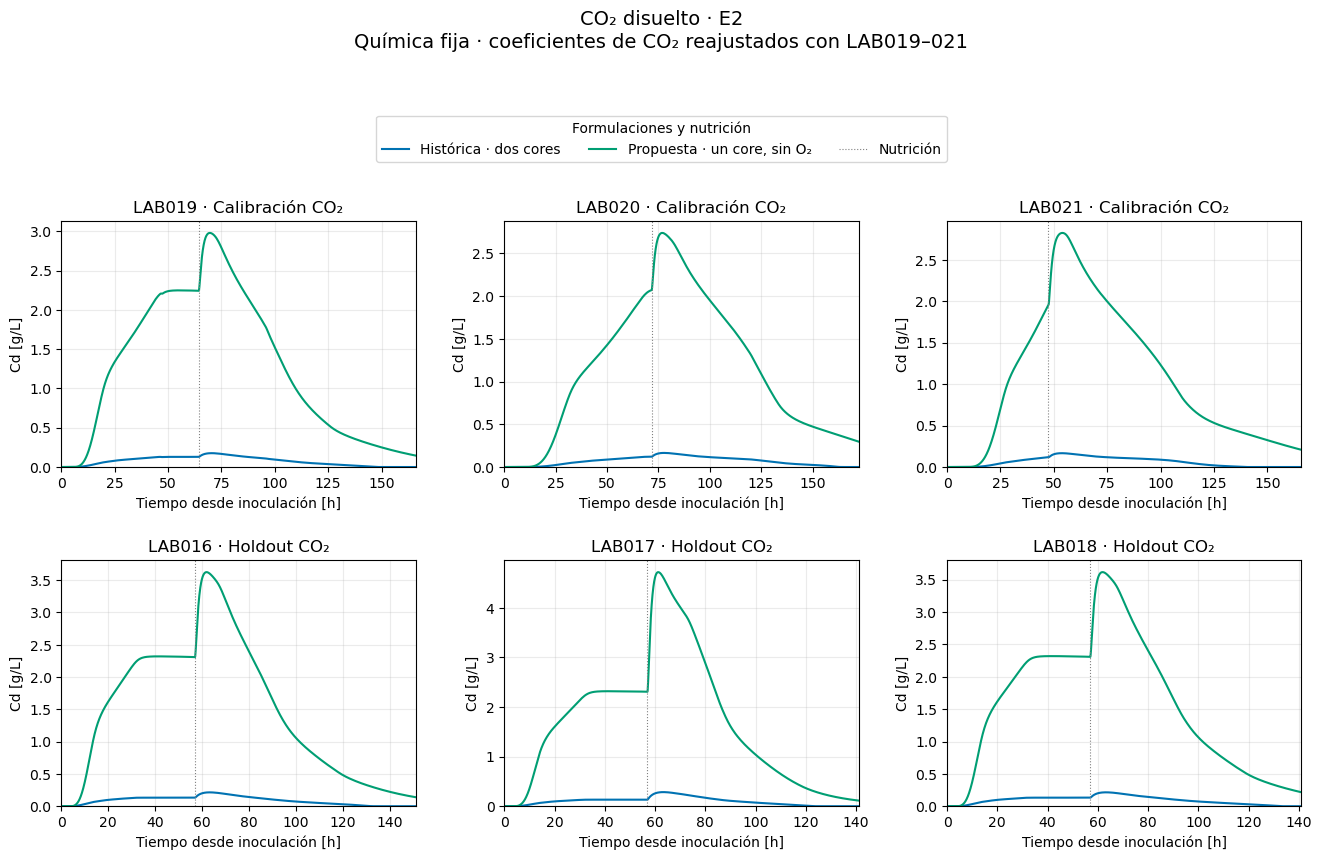

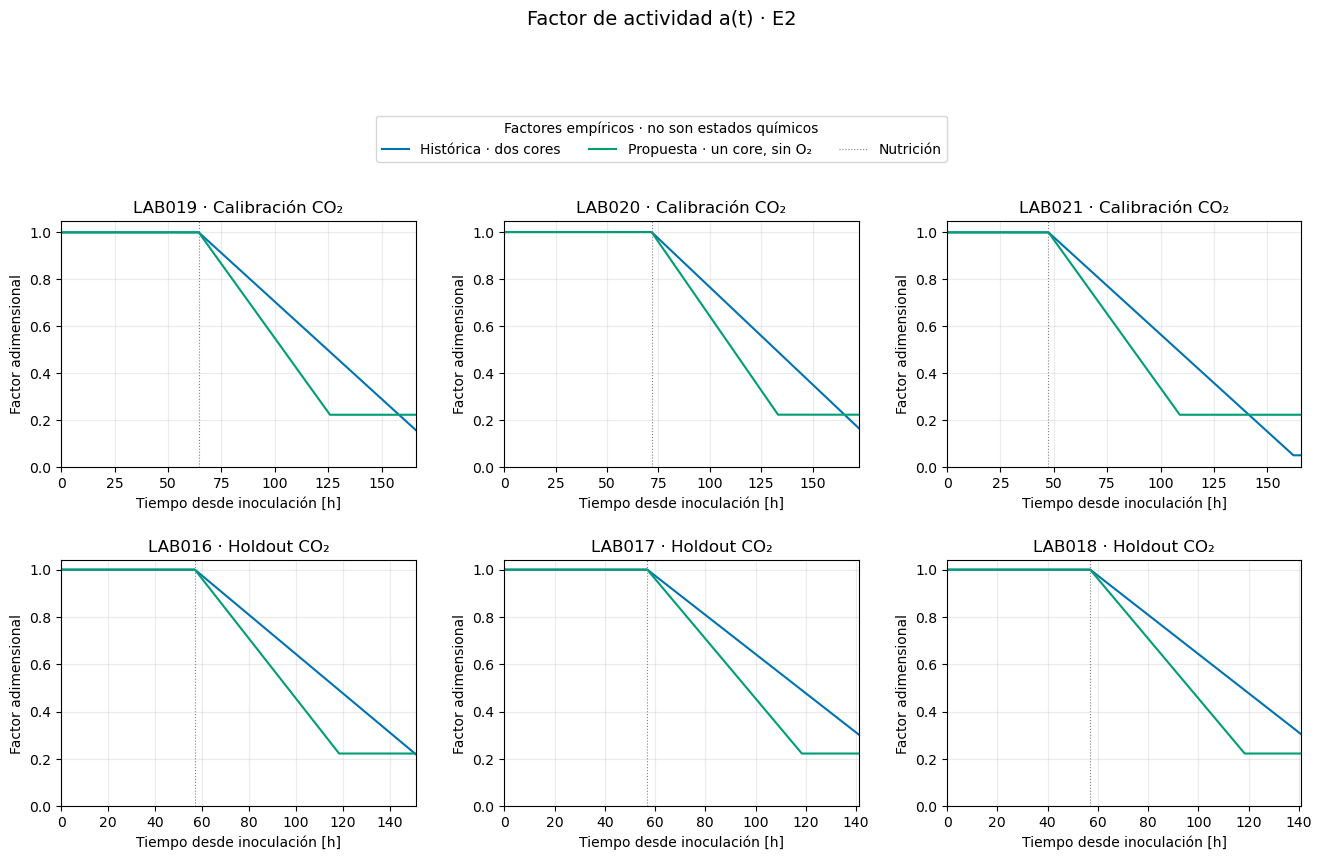

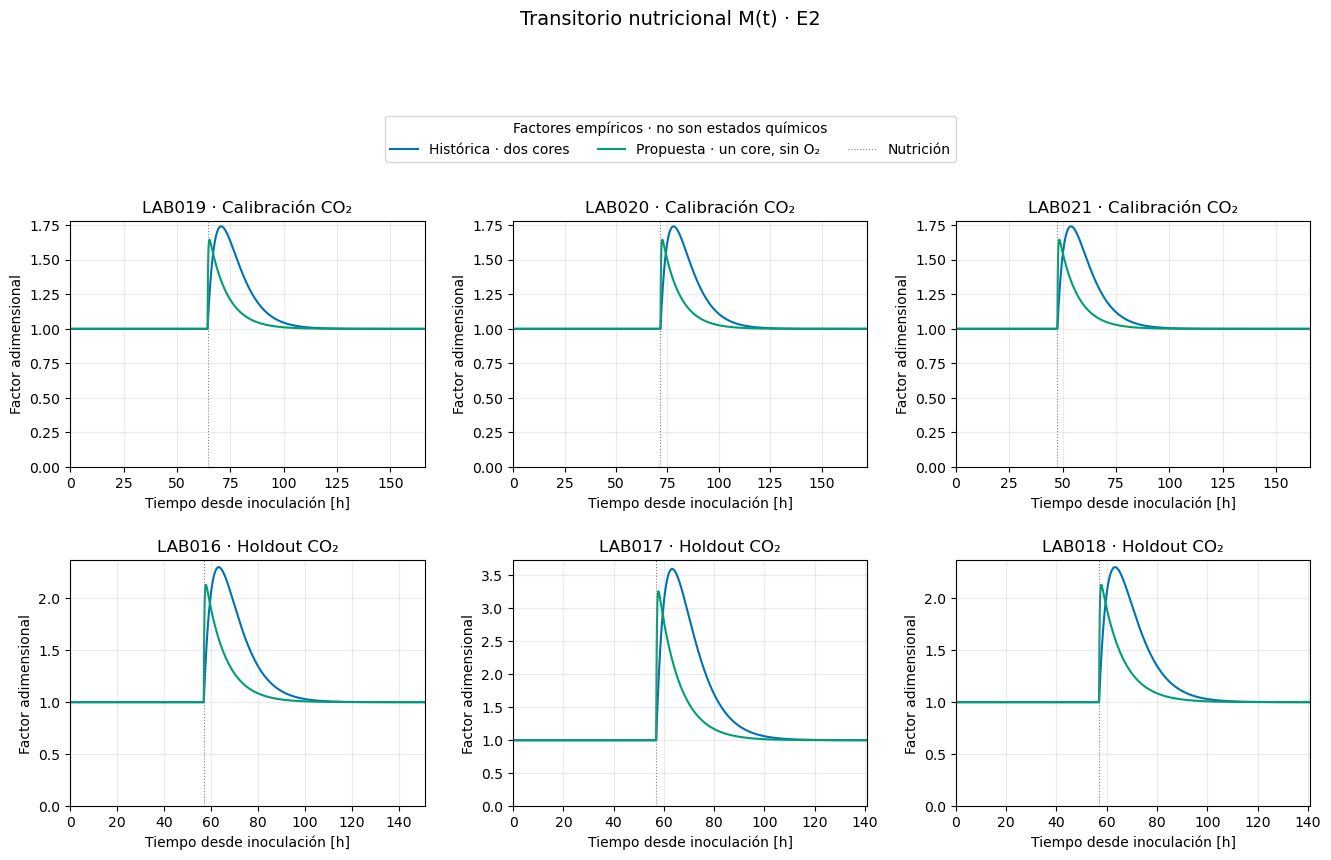

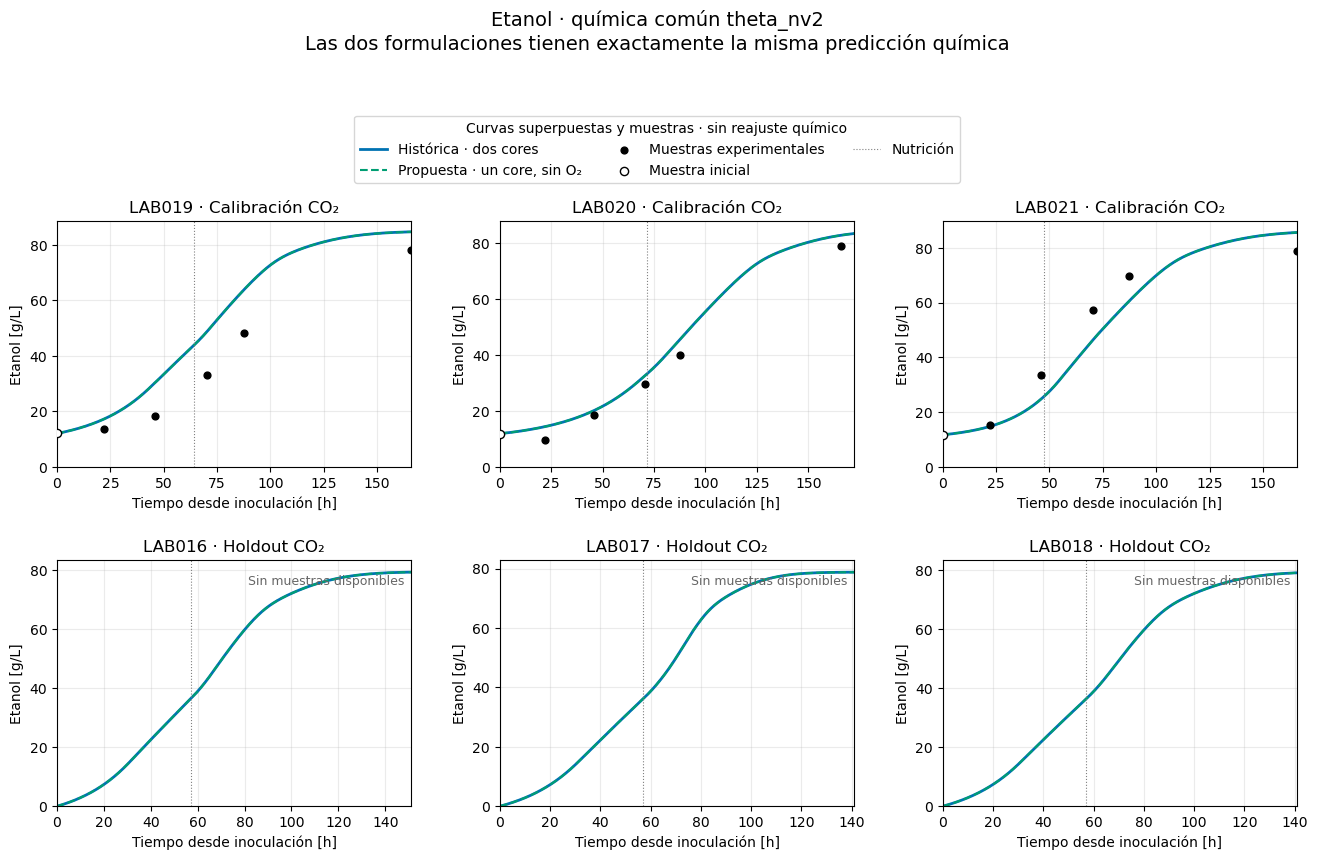

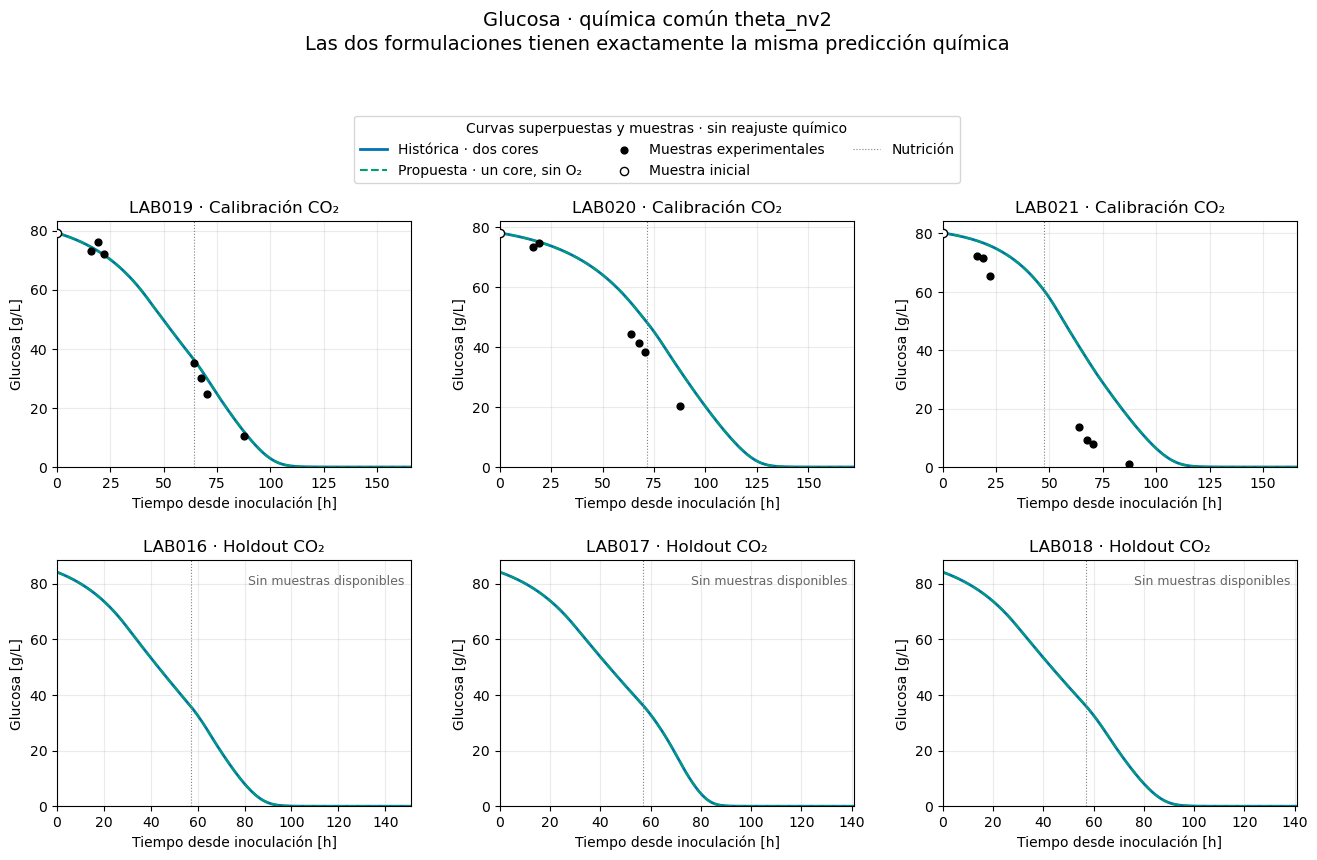

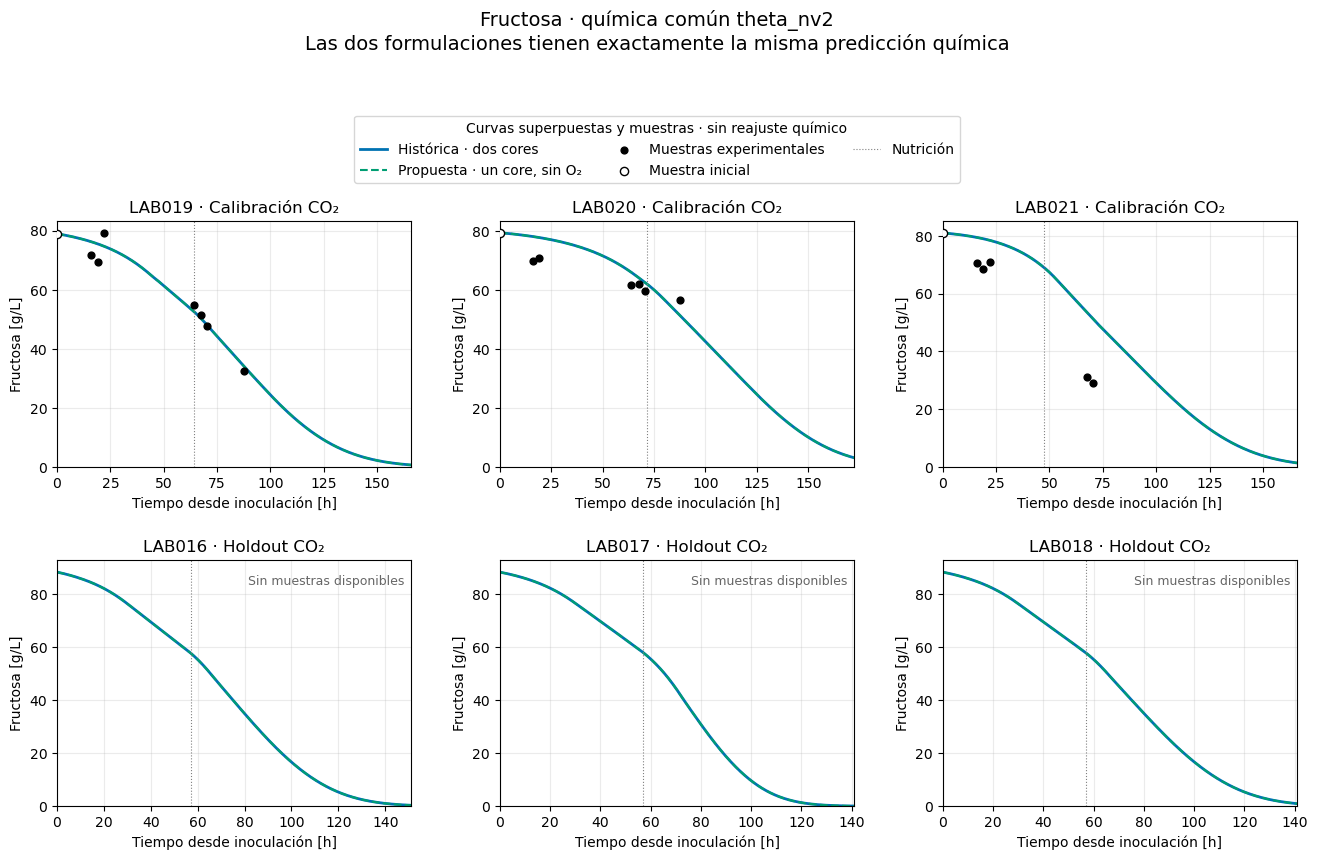

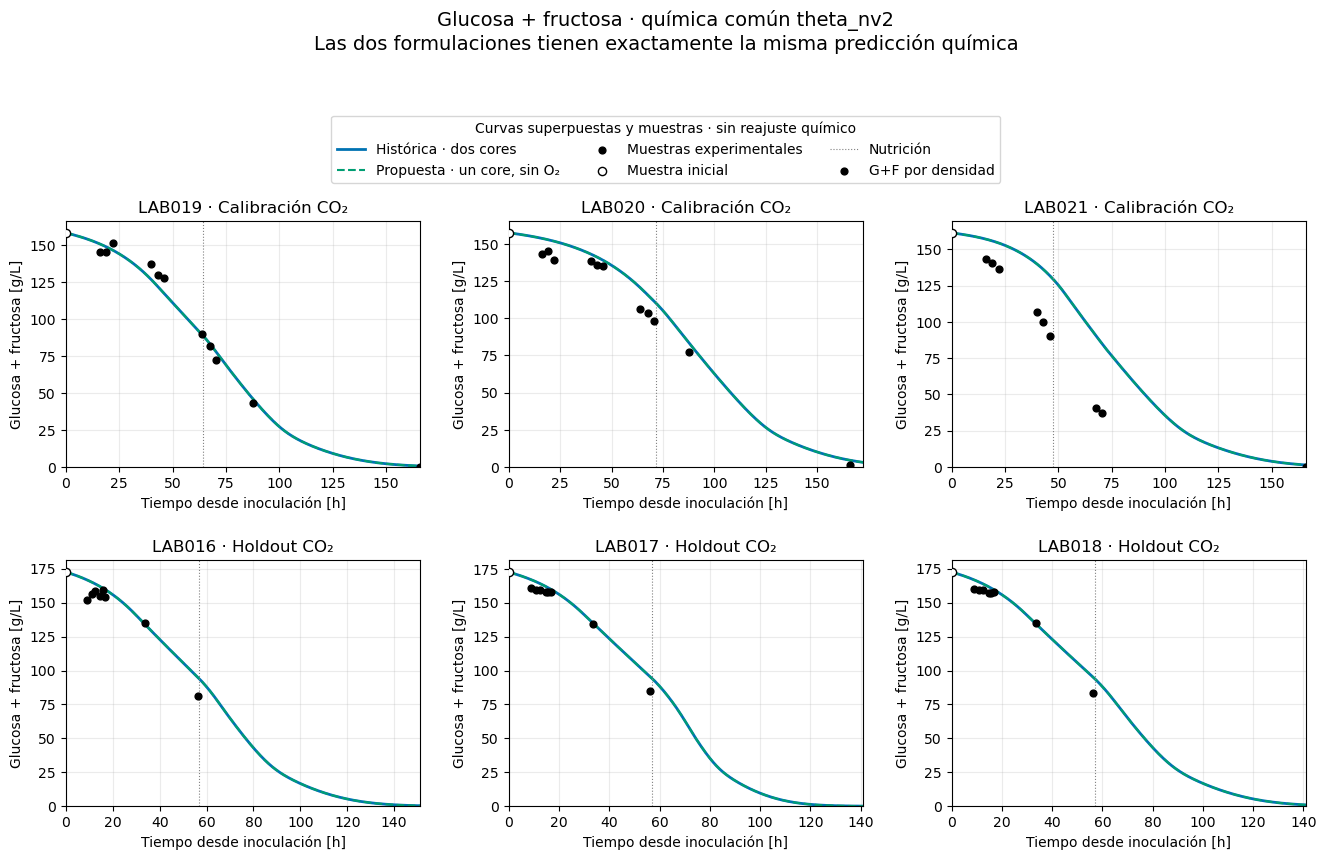

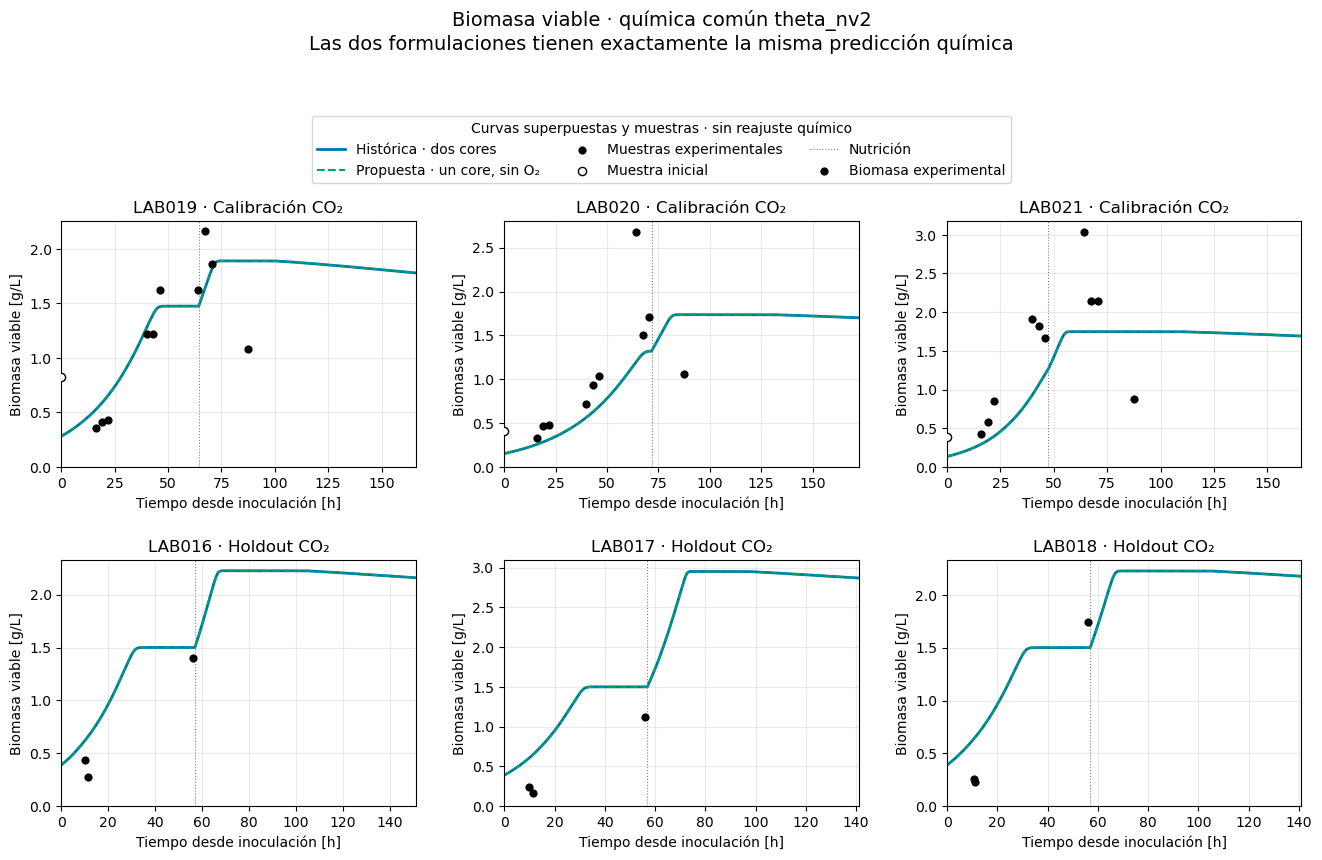

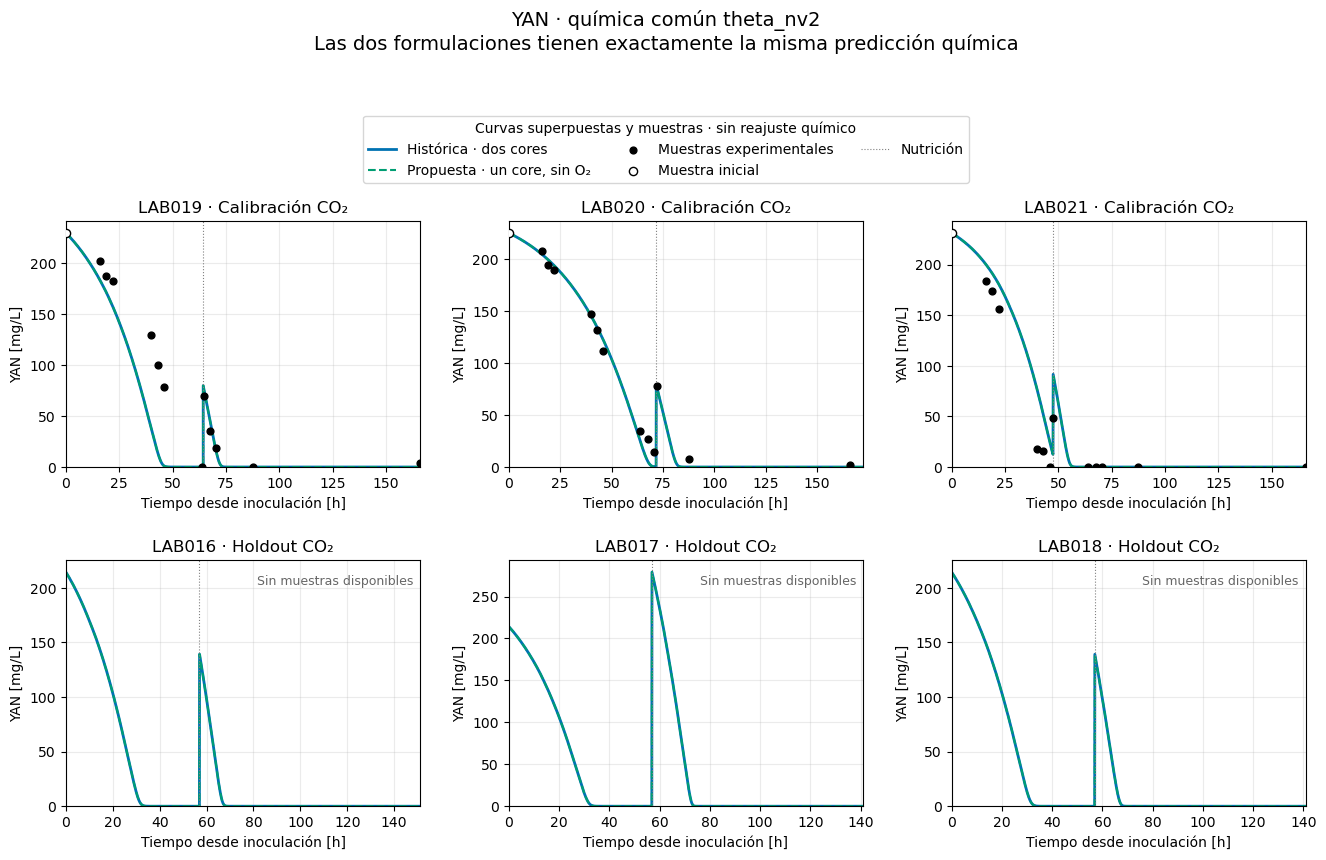

In [5]:
def panels(title,subtitle=''):
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 fig.suptitle(title+('\n'+subtitle if subtitle else ''),y=.995,fontsize=14)
 fig.subplots_adjust(top=.76,hspace=.38,wspace=.25)
 return fig,axes
def legend(fig,axes,title):
 items={}
 for ax in axes.flat:
  h,l=ax.get_legend_handles_labels()
  for hh,ll in zip(h,l):items.setdefault(ll,hh)
 fig.legend(items.values(),items.keys(),loc='upper center',bbox_to_anchor=(.5,.885),ncol=3,title=title)
def decorate(ax,lab,ylabel,lim=None):
 for j,(t,d) in enumerate(batches[lab].pulses['N']):ax.axvline(t,color='.5',ls=':',lw=.8,label='Nutrición' if j==0 else None)
 ax.set(title=lab+(' · Calibración CO₂' if lab in TRAIN else ' · Holdout CO₂'),
  xlabel='Tiempo desde inoculación [h]',ylabel=ylabel)
 ax.set_xlim(0,v.horizons[lab] if lim is None else lim);ax.set_ylim(bottom=0);ax.grid(alpha=.25)
for stage,description in [('E1','Liberación, saturación y ganancia reajustadas'),('E2','Liberación, saturación, ganancia y respuesta nutricional reajustadas')]:
 fig,axes=panels('CO₂ emitido · '+stage,description+'\nCalibración LAB019–021 | Holdout LAB016–018')
 for ax,lab in zip(axes.flat,LABS):
  o=support[lab];ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.1,label='Medianas horarias del sensor')
  for case in CASES:
   f=curves[case,stage,lab].loc[:v.horizons[lab]]
   ax.plot(f.index,f.qpred,color=COLORS[case],lw=1.7,label=case)
  decorate(ax,lab,'CO₂ [g/(L·h)]')
 legend(fig,axes,'Datos y formulaciones · theta_nv2 fijo');plt.show()
# Mechanisms: only the two formulations at E2, in separate figures.
for key,title,ylabel in [('qprod','Producción que entra al depósito','CO₂ [g/(L·h)]'),('Cd','CO₂ disuelto','Cd [g/L]')]:
 fig,axes=panels(title+' · E2','Química fija · coeficientes de CO₂ reajustados con LAB019–021')
 for ax,lab in zip(axes.flat,LABS):
  for case in CASES:
   f=curves[case,'E2',lab].loc[:v.horizons[lab]];ax.plot(f.index,f[key],color=COLORS[case],label=case)
  decorate(ax,lab,ylabel)
 legend(fig,axes,'Formulaciones y nutrición');plt.show()
for kind,title in [('activity','Factor de actividad a(t)'),('multiplier','Transitorio nutricional M(t)')]:
 fig,axes=panels(title+' · E2')
 for ax,lab in zip(axes.flat,LABS):
  for case in CASES:
   c=contexts[case,lab];p=fits[case,'E2'];r,M=Search.histories(c['time'],c['events'],p)
   yy=1+(p['pulse_activity_gain']-1)*r if kind=='activity' else M
   ax.plot(c['time'],yy,color=COLORS[case],label=case)
  decorate(ax,lab,'Factor adimensional')
 legend(fig,axes,'Factores empíricos · no son estados químicos');plt.show()
# All chemical observations; overlapping curves are intentional and asserted identical.
for key,title,scale,unit in VARIABLES:
 fig,axes=panels(title+' · química común theta_nv2','Las dos formulaciones tienen exactamente la misma predicción química')
 for ax,lab in zip(axes.flat,LABS):
  f=contexts[CASES[0],lab]['core']
  ax.plot(f.index,f[key]*scale,color=COLORS[CASES[0]],lw=2,label=CASES[0])
  ax.plot(f.index,f[key]*scale,color=COLORS[CASES[1]],lw=1.5,ls='--',label=CASES[1])
  t,y,label=samples(lab,key);ini=t==0
  if len(t):
   ax.scatter(t[~ini],y[~ini]*scale,color='black',s=24,zorder=5,label=label)
   if ini.any():ax.scatter(t[ini],y[ini]*scale,facecolors='white',edgecolors='black',s=35,zorder=6,label='Muestra inicial')
  else:ax.text(.98,.94,label,ha='right',va='top',transform=ax.transAxes,color='.4',fontsize=9)
  decorate(ax,lab,title+' ['+unit+']',lim=max(v.horizons[lab],float(t.max()) if len(t) else 0))
 legend(fig,axes,'Curvas superpuestas y muestras · sin reajuste químico');plt.show()


In [6]:
display(Markdown('## Verificación y lectura cuantitativa'))
assert theta==theta_before
assert integration_calls=={CASES[0]:12,CASES[1]:6}
assert all(not {'q0','core0','fferm','oxygen0'}.intersection(contexts[CASES[1],lab]) for lab in LABS)
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in before.items())
print('VERIFICADO: theta_nv2, modelos, parámetros y archivos previos intactos.')
print('Propuesta: seis integraciones químicas para seis LAB, ninguna trayectoria sin dosis.')
display(metrics.groupby(['etapa','rol','caso']).RMSE.mean().unstack('caso').round(6))
for case in CASES:
 p=fits[case,'E2'];row=next(r for r in fitrows if r['caso']==case and r['etapa']=='E2')
 print(case,'E2; cerca de límites:',row['cerca_limites'],'ratio singular:',row['ratio_singular'])
 display(pd.DataFrame([dict(parametro=k,valor=p[k]) for k in (*GAS_NAMES,*NUT_NAMES)]))
print('Se informan ambos ajustes locales y ambos holdouts; no se garantiza mejora ni observabilidad de X/YAN.')
print('Qprod incluye factores empíricos de actividad; no es una producción estequiométrica exacta. La capa de gas no realimenta la química.')


## Verificación y lectura cuantitativa

VERIFICADO: theta_nv2, modelos, parámetros y archivos previos intactos.
Propuesta: seis integraciones químicas para seis LAB, ninguna trayectoria sin dosis.


caso               Histórica · dos cores  Propuesta · un core, sin O₂
etapa rol                                                            
E1    Calibración               0.133468                     0.130951
      Holdout                   0.122912                     0.157588
E2    Calibración               0.127371                     0.129549
      Holdout                   0.214679                     0.195681

Histórica · dos cores E2; cerca de límites: kCO2_release_h,CO2sat_scale,pulse_activity_gain,tau_rise_h ratio singular: 0.00015839380668660356


,parametro,valor
0,kCO2_release_h,25.000000
1,CO2sat_scale,0.350000
2,matrix_gain,0.698482
3,pulse_activity_gain,0.050000
4,pulse_t_rise_h,114.690555
5,A,1.297543
6,tau_rise_h,24.000000
7,tau_decay_h,7.296109


Propuesta · un core, sin O₂ E2; cerca de límites: CO2sat_scale,tau_rise_h ratio singular: 0.0028291600477910106


,parametro,valor
0,kCO2_release_h,0.831795
1,CO2sat_scale,2.500000
2,matrix_gain,0.746271
3,pulse_activity_gain,0.222743
4,pulse_t_rise_h,61.503466
5,A,1.129288
6,tau_rise_h,0.250000
7,tau_decay_h,8.472341


Se informan ambos ajustes locales y ambos holdouts; no se garantiza mejora ni observabilidad de X/YAN.
Qprod incluye factores empíricos de actividad; no es una producción estequiométrica exacta. La capa de gas no realimenta la química.


## Resultado del ensayo

RMSE ordinario medio por laboratorio, g/(L·h); no confundir con el objetivo censurado optimizado:

| Etapa | Formulación | Calibración LAB019–021 | Holdout LAB016–018 |
|---|---|---:|---:|
| E1: tres coeficientes | Histórica · dos cores | 0.133468 | 0.122912 |
| E1: tres coeficientes | Propuesta · un core, sin O₂ | 0.130951 | 0.157588 |
| E2: también respuesta nutricional | Histórica · dos cores | 0.127371 | 0.214679 |
| E2: también respuesta nutricional | Propuesta · un core, sin O₂ | 0.129549 | 0.195681 |

La propuesta **sí elimina la segunda simulación**, manteniendo la misma química nutrida y la estructura fuente-depósito-liberación. Eso no basta para mejorar la generalización: con respuesta nutricional fija (E1), su holdout es peor que el histórico. En E2 la propuesta queda mejor que la histórica E2, pero ambos empeoran respecto a sus respectivas E1. Los doce arranques terminaron con convergencia; esto no demuestra óptimo global ni identificabilidad única.

Liberar la respuesta nutricional reduce el objetivo de calibración, pero aumenta los picos de holdout. En la propuesta E2: A=1.129288, tau_r=0.25 h (cota inferior), tau_d=8.472341 h, actividad final=0.222743, rampa=61.503466 h, liberación=0.831795 h⁻¹, escala Csat=2.5 (cota superior) y ganancia=0.746271. En LAB017 el pico horario predicho pasa de 1.1713 en E1 a 1.6414 en E2, frente al medido 0.8534 g/(L·h).

Hay una extrapolación de dosis explícita: calibración con pulsos de 0.08 g/L y holdout con 0.14/0.28/0.14 g/L. El transitorio escala linealmente con dosis; en la propuesta E2, M alcanza 1+A·0.28/0.14≈3.26 para el pulso único de LAB017. Es una razón concreta para la amplificación observada; no se está simulando un segundo pulso. También cambian la química y condiciones iniciales entre LAB, por lo que no se atribuye toda la diferencia sólo a esa escala.

La histórica E2 alcanza liberación=25 h⁻¹, escala Csat=0.35, actividad final=0.05 y tau_r=24 h, todos en cotas. La sensibilidad más débil del Jacobiano y estas cotas advierten compensaciones entre parámetros. La escala Csat alcanza 2.5 en ambas E1 y en la propuesta E2. No se interpreta ninguno de estos valores como una medición física independiente.

Las curvas químicas de ambas formulaciones son exactamente iguales, con muestras incluidas: no hubo recalibración química ni realimentación del gas a etanol, azúcares, biomasa o YAN. Por tanto, este ensayo no demuestra observabilidad de X/YAN ni corrige errores químicos.

El JSON completo imprime también opciones heredadas por trazabilidad. Las opciones chem_activation_start_fraction y chem_activation_duration_fraction no intervienen en estas ecuaciones: el gate efectivo es el consumo 2–10 g/L documentado. Los parámetros específicos de O₂ sólo se evalúan en la histórica y no intervienen en la propuesta.

La comparación retira O₂ además de eliminar core0. No permite atribuir causalmente todo cambio a uno solo de esos dos cambios. Todos los parámetros nuevos quedan dentro del notebook; originales verificados por hashes. No se exportaron CSV/PNG al proyecto.
